In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.subsampling import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../data/data_final.csv")

diagnosis_variables = []

with open("../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [6]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [7]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Test events: 6.0


In [8]:
subsampling = survival_dataset.iloc[train_index].copy()

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Train and Test Final Model with Best Hyperparameters

In [9]:
# Load best hyperparameters from corrected_sub_results
best_results = pd.read_csv("../results/corrected_sub_results/cox_subsampling_grid_search_results.csv")
# Select row with highest c_index_ipcw_mean
best_params = best_results.sort_values('c_index_ipcw_mean', ascending=False).iloc[0]

print("Best hyperparameters:")
print(f"  sampling_ratio: {best_params['sampling_ratio']}")
print(f"  rank_ratio: {best_params['rank_ratio']}")
print(f"  alpha: {best_params['alpha']}")
print(f"  c_index_ipcw_mean (CV): {best_params['c_index_ipcw_mean']:.4f}")
print()

Best hyperparameters:
  sampling_ratio: 2.0
  rank_ratio: 1.0
  alpha: 0.1
  c_index_ipcw_mean (CV): 0.7590



In [10]:
# Prepare training fold dataframe (subsampling variable was created earlier)
train_fold = subsampling.copy()

# Apply case-control subsampling
x_train_sub, y_train_sub, sub_dataset = sample_case_control(
    train_fold=train_fold,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_controls_per_case=int(best_params['sampling_ratio']),
    feature_columns=feature_columns,
    random_state=12
)

print(f"Original training samples: {len(x_train)}")
print(f"Subsampled training samples: {len(x_train_sub)}")
print(f"Test samples: {len(x_test)}")

Original training samples: 2376
Subsampled training samples: 81
Test samples: 594


In [11]:
# Train final model with best hyperparameters
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
x_train_sub_scaled = scaler.fit_transform(x_train_sub)

final_model = CoxnetSurvivalAnalysis(
    l1_ratio=best_params['rank_ratio'],
    alphas=[best_params['alpha']],  # Use the specific alpha value found during grid search
    fit_baseline_model=True
)

final_model.fit(x_train_sub_scaled, y_train_sub)
print("Model trained successfully!")

Model trained successfully!


In [12]:
# Test the model on test set
x_test_scaled = scaler.transform(x_test)

# Calculate c-index
c_index = final_model.score(x_test_scaled, y_test)

# Calculate c-index IPCW
tau = y_train_sub["time"].max()
c_index_ipcw = concordance_index_ipcw(y_train_sub, y_test, final_model.predict(x_test_scaled), tau=tau)[0]

# Calculate integrated Brier score
surv_funcs = final_model.predict_survival_function(x_test_scaled)

# Use robust time filtering
max_time = min(y_train_sub['time'].max(), y_test['time'].max()) * 0.9

# Use percentile-based times (5% to 90%)
times = np.percentile(y_train_sub['time'], np.linspace(5, 90, 10))
# Ensure times are unique and sorted
times = np.unique(times)
# Filter times that are within valid range
times = times[(times > 0) & (times <= max_time)]

preds_at_times = np.array([[fn(t) for t in times] for fn in surv_funcs])
brier_score = integrated_brier_score(y_train_sub, y_test, preds_at_times, times)

print("\\nTest Set Performance:")
print(f"  C-index: {c_index:.4f}")
print(f"  C-index IPCW: {c_index_ipcw:.4f}")
print(f"  Integrated Brier Score: {brier_score:.4f}")

\nTest Set Performance:
  C-index: 0.7607
  C-index IPCW: 0.7391
  Integrated Brier Score: 0.0240


# Cox-based Recalibration (Harrell Method)

In [13]:
# Step 1: Extract risk scores from the original model on full training data
print("="*60)
print("Step 1: Extract Risk Scores from Original Model")
print("="*60)

# Get risk scores (predictions) from the original model trained on subsampled data
# These will be used as the single predictor in the Cox recalibration model
x_train_scaled = scaler.transform(x_train)
train_risk_scores = final_model.predict(x_train_scaled)

print(f"\nOriginal model trained on: {len(x_train_sub)} subsampled samples")
print(f"Risk scores calculated for: {len(x_train)} samples (full training set)")
print(f"Risk score range: [{train_risk_scores.min():.4f}, {train_risk_scores.max():.4f}]")
print(f"Risk score mean: {train_risk_scores.mean():.4f}")
print(f"Risk score std: {train_risk_scores.std():.4f}")

Step 1: Extract Risk Scores from Original Model

Original model trained on: 81 subsampled samples
Risk scores calculated for: 2376 samples (full training set)
Risk score range: [-0.7395, 1.1566]
Risk score mean: -0.1514
Risk score std: 0.4210


In [14]:
# Step 2: Fit Cox model on risk scores to get calibration slope
print("\n" + "="*60)
print("Step 2: Fit Cox Model on Risk Scores")
print("="*60)

# Reshape risk scores to be a 2D array (required by scikit-survival)
x_train_risk = train_risk_scores.reshape(-1, 1)

# Fit a Cox model using the risk scores as the single predictor
cox_recal_model = CoxPHSurvivalAnalysis()
cox_recal_model.fit(x_train_risk, y_train)

# Extract the calibration slope (coefficient of the Cox model)
calibration_slope = cox_recal_model.coef_[0]

print(f"\nCox recalibration model fitted successfully!")
print(f"Calibration slope (β): {calibration_slope:.4f}")
print("\nInterpretation:")
if abs(calibration_slope - 1.0) < 0.1:
    print("  ✓ Calibration slope ≈ 1.0: Model is well-calibrated")
elif calibration_slope < 1.0:
    print(f"  ⚠ Calibration slope < 1.0: Predictions are too extreme (overconfident)")
else:
    print(f"  ⚠ Calibration slope > 1.0: Predictions are too moderate (underconfident)")

print(f"\nTraining data:")
print(f"  Samples: {len(x_train)}")
print(f"  Events: {y_train['event'].sum()} ({y_train['event'].mean()*100:.1f}%)")


Step 2: Fit Cox Model on Risk Scores

Cox recalibration model fitted successfully!
Calibration slope (β): 1.9305

Interpretation:
  ⚠ Calibration slope > 1.0: Predictions are too moderate (underconfident)

Training data:
  Samples: 2376
  Events: 27 (1.1%)


In [15]:
# Step 3: Create recalibrated prediction function
print("\n" + "="*60)
print("Step 3: Define Recalibrated Prediction Function")
print("="*60)

def predict_survival_recalibrated_cox(original_model, cox_model, X, times):
    """
    Predict recalibrated survival probabilities using Cox-based recalibration.
    
    Parameters:
    -----------
    original_model : CoxnetSurvivalAnalysis
        Original model trained on subsampled data
    cox_model : CoxPHSurvivalAnalysis
        Cox model fitted on risk scores for recalibration
    X : array-like, shape (n_samples, n_features)
        Test samples (SCALED)
    times : array-like
        Time points at which to predict survival
    
    Returns:
    --------
    survival_probs : array, shape (n_samples, n_times)
        Recalibrated survival probabilities
    """
    # Get risk scores from original model
    risk_scores = original_model.predict(X)
    
    # Reshape for Cox model
    risk_scores_2d = risk_scores.reshape(-1, 1)
    
    # Get recalibrated survival functions from Cox model
    surv_funcs_recal = cox_model.predict_survival_function(risk_scores_2d)
    
    # Extract survival probabilities at specified times
    survival_probs = np.array([[fn(t) for t in times] for fn in surv_funcs_recal])
    
    return survival_probs

print("\nRecalibrated prediction function created!")
print("This function:")
print("  1. Takes risk scores from the original model")
print("  2. Passes them through the Cox recalibration model")
print("  3. Returns recalibrated survival probabilities")


Step 3: Define Recalibrated Prediction Function

Recalibrated prediction function created!
This function:
  1. Takes risk scores from the original model
  2. Passes them through the Cox recalibration model
  3. Returns recalibrated survival probabilities


In [19]:
# Step 4: Evaluate recalibrated model performance
print("\n" + "="*60)
print("Step 4: Evaluate Model Performance")
print("="*60)

# Prepare test data
x_test_scaled = scaler.transform(x_test)

# Get risk scores for C-index calculation
test_risk_scores = final_model.predict(x_test_scaled)

print("\n--- Before Recalibration (Original Model) ---")
print(f"C-index: {c_index:.4f}")
print(f"C-index IPCW: {c_index_ipcw:.4f}")
print(f"Integrated Brier Score: {brier_score:.4f}")

# Calculate metrics after recalibration
# For C-index (discrimination is unchanged by recalibration)
c_index_recal = concordance_index_censored(y_test['event'], y_test['time'], test_risk_scores)[0]

# For C-index IPCW
tau_recal = y_train["time"].max()
c_index_ipcw_recal = concordance_index_ipcw(y_train_sub, y_test, test_risk_scores, tau=tau_recal)[0]

# For Brier score, we need survival probabilities at specific times
max_time_recal = min(y_train['time'].max(), y_test['time'].max()) * 0.9
times_recal = np.percentile(y_train['time'], np.linspace(5, 90, 10))
times_recal = np.unique(times_recal)
times_recal = times_recal[(times_recal > 0) & (times_recal <= max_time_recal)]

# Get recalibrated survival predictions
survival_preds_recal = predict_survival_recalibrated_cox(
    final_model, cox_recal_model, x_test_scaled, times_recal
)

# Calculate Brier score
brier_score_recal = integrated_brier_score(y_train, y_test, survival_preds_recal, times_recal)

print("\n--- After Recalibration (Cox-based Harrell Method) ---")
print(f"C-index: {c_index_recal:.4f}")
print(f"C-index IPCW: {c_index_ipcw_recal:.4f}")
print(f"Integrated Brier Score: {brier_score_recal:.4f}")

print("\n--- Improvement ---")
print(f"ΔC-index: {c_index_recal - c_index:+.4f}")
print(f"ΔC-index IPCW: {c_index_ipcw_recal - c_index_ipcw:+.4f}")
print(f"ΔBrier Score: {brier_score_recal - brier_score:+.4f} (lower is better)")

if brier_score_recal < brier_score:
    improvement_pct = (brier_score - brier_score_recal) / brier_score * 100
    print(f"Brier score improved by {improvement_pct:.1f}%")
print("="*60)


Step 4: Evaluate Model Performance

--- Before Recalibration (Original Model) ---
C-index: 0.7607
C-index IPCW: 0.7391
Integrated Brier Score: 0.0240

--- After Recalibration (Cox-based Harrell Method) ---
C-index: 0.7607
C-index IPCW: 0.7391
Integrated Brier Score: 0.0078

--- Improvement ---
ΔC-index: +0.0000
ΔC-index IPCW: +0.0000
ΔBrier Score: -0.0162 (lower is better)
Brier score improved by 67.5%



Step 5: Generate Calibration Plots
Calibration comparison plot saved as 'cox_calibration_comparison.png'

Optimized timepoints based on event distribution:
  650 days (1.8 years) - 25th percentile
  1100 days (3.0 years) - Median
  1600 days (4.4 years) - 75th percentile
  1825 days (5.0 years) - Captures 85% of events


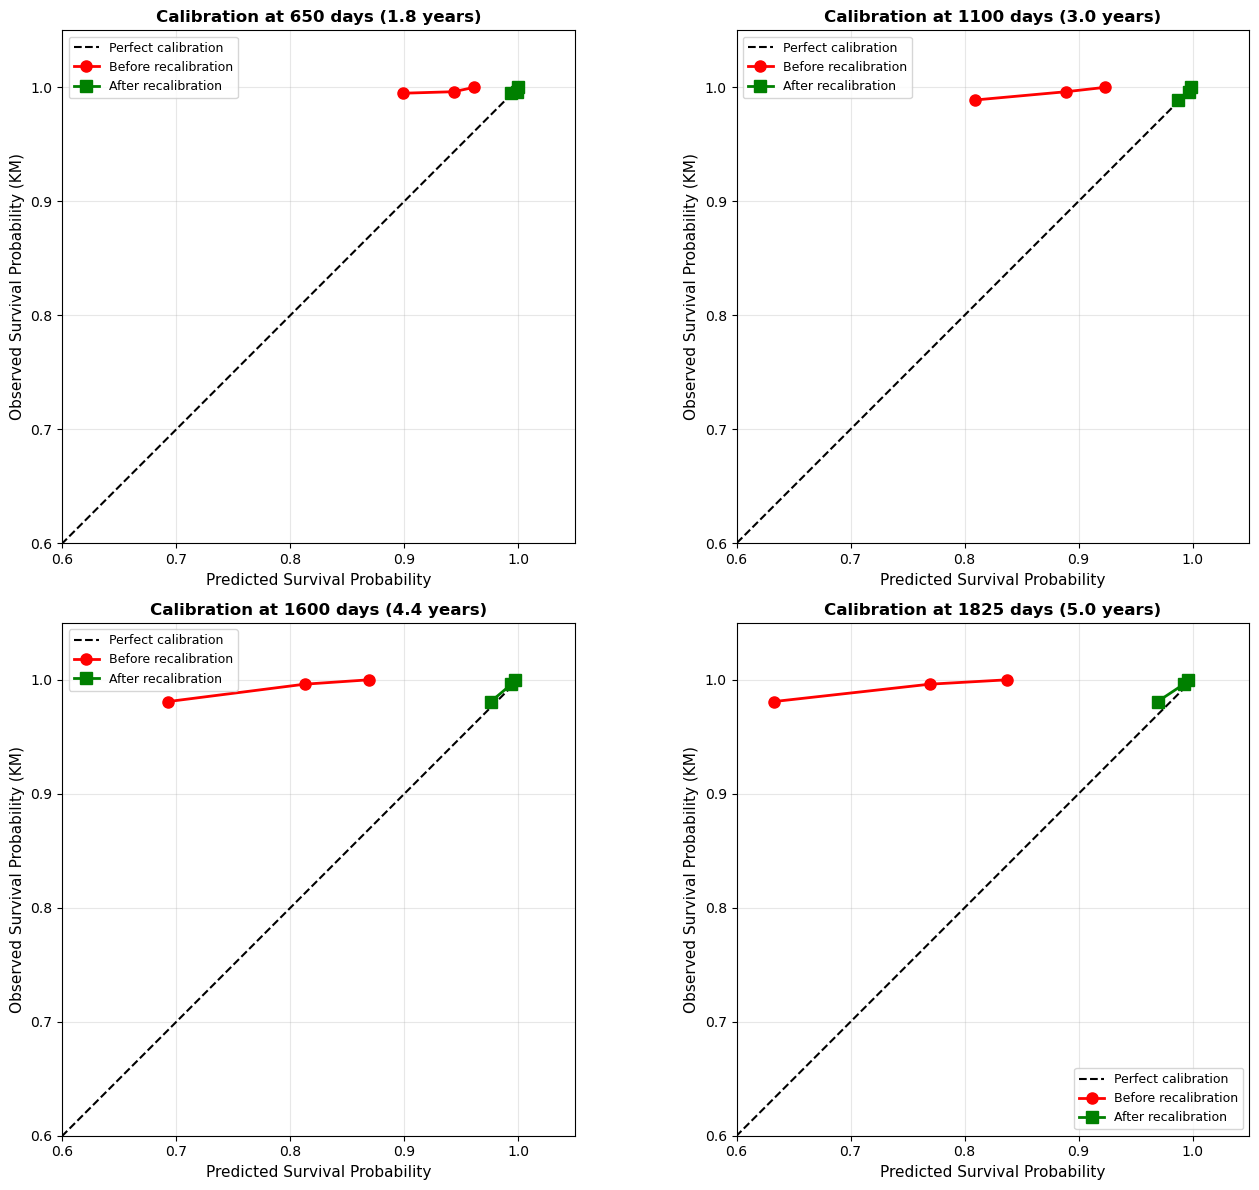

In [17]:
# Step 5: Calibration plot - Before vs After Recalibration
print("\n" + "="*60)
print("Step 5: Generate Calibration Plots")
print("="*60)

import matplotlib.pyplot as plt

# Time points for calibration - optimized based on event distribution quartiles
# 650 days (~1.8 years, 25th percentile), 1100 days (~3 years, median), 
# 1600 days (~4.4 years, 75th percentile), 1825 days (5 years, captures 85% of events)
time_points = [650, 1100, 1600, 1825]
n_bins = 3  # Low, medium, high risk groups

# Get predictions for both models
# Before recalibration: Use final_model (trained on subsampled data)
x_test_scaled_plot = scaler.transform(x_test)
surv_funcs_before = final_model.predict_survival_function(x_test_scaled_plot)

# After recalibration: Use Cox-based recalibration
times_for_calib = np.array(time_points)
survival_preds_after = predict_survival_recalibrated_cox(
    final_model, cox_recal_model, x_test_scaled_plot, times_for_calib
)

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for idx, time_point in enumerate(time_points):
    ax = axes[idx]
    
    # Get predictions at this time point
    # Before recalibration
    pred_surv_before = np.array([fn(time_point) for fn in surv_funcs_before])
    
    # After recalibration
    pred_surv_after = survival_preds_after[:, idx]
    
    # Create risk groups based on predicted risk (1 - survival probability)
    # Use the recalibrated predictions for binning
    risk_scores = 1 - pred_surv_after
    bin_edges = np.percentile(risk_scores, [0, 33.33, 66.67, 100])
    bin_edges[0] = -np.inf  # Ensure all values are included
    bin_edges[-1] = np.inf
    bin_indices = np.digitize(risk_scores, bin_edges[1:-1])
    
    # Calculate mean predicted and observed survival for each bin
    mean_pred_before = []
    mean_pred_after = []
    mean_observed = []
    
    for bin_idx in range(n_bins):
        mask = bin_indices == bin_idx
        
        if mask.sum() == 0:
            continue
        
        # Mean predicted survival - before
        mean_pred_before.append(pred_surv_before[mask].mean())
        
        # Mean predicted survival - after
        mean_pred_after.append(pred_surv_after[mask].mean())
        
        # Observed survival using Kaplan-Meier
        km_time, km_prob = kaplan_meier_estimator(
            y_test['event'][mask],
            y_test['time'][mask]
        )
        
        # Interpolate to get survival at time_point
        if time_point <= km_time.min():
            obs_surv = 1.0
        elif time_point >= km_time.max():
            obs_surv = km_prob[-1]
        else:
            obs_surv = np.interp(time_point, km_time, km_prob)
        
        mean_observed.append(obs_surv)
    
    # Plot calibration
    # Perfect calibration line
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)
    
    # Before recalibration
    ax.plot(mean_pred_before, mean_observed, 'o-', 
            label='Before recalibration', 
            color='red', markersize=8, linewidth=2)
    
    # After recalibration
    ax.plot(mean_pred_after, mean_observed, 's-', 
            label='After recalibration', 
            color='green', markersize=8, linewidth=2)
    
    ax.set_xlabel('Predicted Survival Probability', fontsize=11)
    ax.set_ylabel('Observed Survival Probability (KM)', fontsize=11)
    ax.set_title(f'Calibration at {time_point} days ({time_point/365:.1f} years)', 
                 fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0.6, 1.05)
    ax.set_ylim(0.6, 1.05)
    ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('cox_calibration_comparison.png', dpi=300, bbox_inches='tight')
print("Calibration comparison plot saved as 'cox_calibration_comparison.png'")

print(f"\nOptimized timepoints based on event distribution:")
print(f"  {time_points[0]} days ({time_points[0]/365:.1f} years) - 25th percentile")
print(f"  {time_points[1]} days ({time_points[1]/365:.1f} years) - Median")
print(f"  {time_points[2]} days ({time_points[2]/365:.1f} years) - 75th percentile")
print(f"  {time_points[3]} days ({time_points[3]/365:.1f} years) - Captures 85% of events")
plt.show()


Event Time Distribution Analysis

Training Set (27 events):
  Min event time: 75 days
  25th percentile: 668 days
  Median: 1106 days
  75th percentile: 1619 days
  Max event time: 5381 days

Test Set (6 events):
  Min event time: 323 days
  25th percentile: 650 days
  Median: 1035 days
  75th percentile: 1708 days
  Max event time: 4103 days

Percentage of events occurring BEFORE each timepoint:

At 365 days (1.0 years):
  Training: 14.8% of events
  Test: 16.7% of events

At 730 days (2.0 years):
  Training: 29.6% of events
  Test: 33.3% of events

At 1095 days (3.0 years):
  Training: 48.1% of events
  Test: 50.0% of events

At 1825 days (5.0 years):
  Training: 85.2% of events
  Test: 66.7% of events

At 730 days (2.0 years):
  Training: 29.6% of events
  Test: 33.3% of events

At 1095 days (3.0 years):
  Training: 48.1% of events
  Test: 50.0% of events

At 1460 days (4.0 years):
  Training: 66.7% of events
  Test: 66.7% of events

At 1825 days (5.0 years):
  Training: 85.2% of e

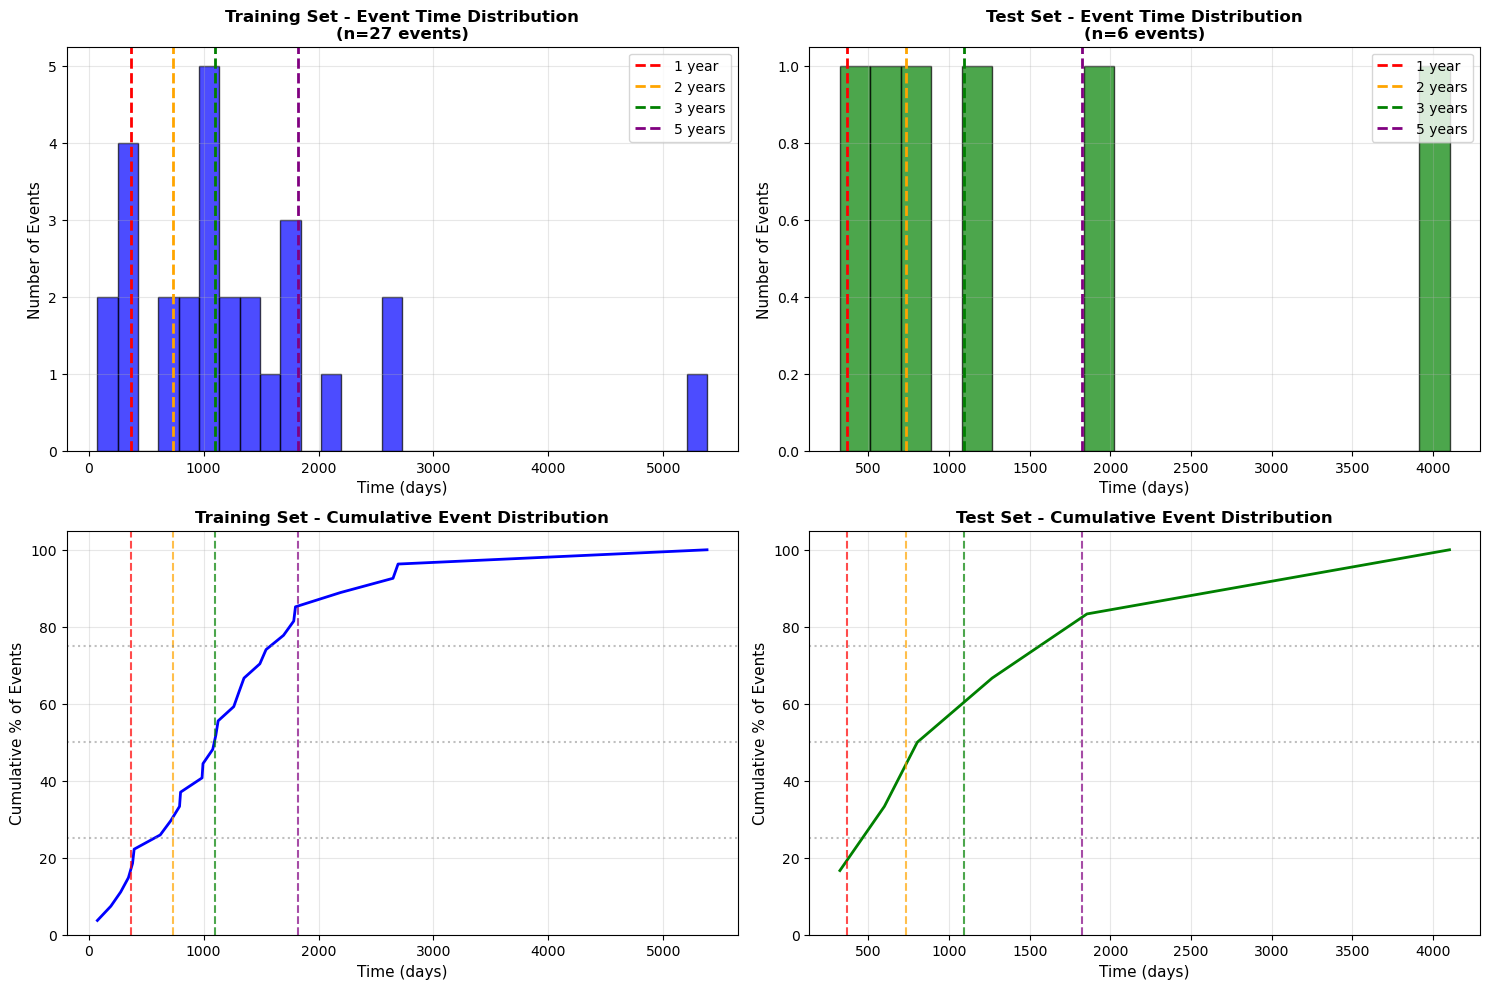

In [18]:
# Analyze event time distribution to determine optimal timeframes
import matplotlib.pyplot as plt
import numpy as np

# Get event times from training and test data
train_event_times = y_train['time'][y_train['event'] == 1]
test_event_times = y_test['time'][y_test['event'] == 1]

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Histogram of event times - Training
axes[0, 0].hist(train_event_times, bins=30, edgecolor='black', alpha=0.7, color='blue')
axes[0, 0].axvline(365, color='red', linestyle='--', label='1 year', linewidth=2)
axes[0, 0].axvline(730, color='orange', linestyle='--', label='2 years', linewidth=2)
axes[0, 0].axvline(1095, color='green', linestyle='--', label='3 years', linewidth=2)
axes[0, 0].axvline(1825, color='purple', linestyle='--', label='5 years', linewidth=2)
axes[0, 0].set_xlabel('Time (days)', fontsize=11)
axes[0, 0].set_ylabel('Number of Events', fontsize=11)
axes[0, 0].set_title(f'Training Set - Event Time Distribution\n(n={len(train_event_times)} events)', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Histogram of event times - Test
axes[0, 1].hist(test_event_times, bins=20, edgecolor='black', alpha=0.7, color='green')
axes[0, 1].axvline(365, color='red', linestyle='--', label='1 year', linewidth=2)
axes[0, 1].axvline(730, color='orange', linestyle='--', label='2 years', linewidth=2)
axes[0, 1].axvline(1095, color='green', linestyle='--', label='3 years', linewidth=2)
axes[0, 1].axvline(1825, color='purple', linestyle='--', label='5 years', linewidth=2)
axes[0, 1].set_xlabel('Time (days)', fontsize=11)
axes[0, 1].set_ylabel('Number of Events', fontsize=11)
axes[0, 1].set_title(f'Test Set - Event Time Distribution\n(n={len(test_event_times)} events)', fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Cumulative distribution of events - Training
sorted_train_times = np.sort(train_event_times)
cumulative_train = np.arange(1, len(sorted_train_times) + 1) / len(sorted_train_times) * 100
axes[1, 0].plot(sorted_train_times, cumulative_train, linewidth=2, color='blue')
axes[1, 0].axvline(365, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axvline(730, color='orange', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axvline(1095, color='green', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axvline(1825, color='purple', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 0].axhline(25, color='gray', linestyle=':', alpha=0.5, label='Quartiles')
axes[1, 0].axhline(50, color='gray', linestyle=':', alpha=0.5)
axes[1, 0].axhline(75, color='gray', linestyle=':', alpha=0.5)
axes[1, 0].set_xlabel('Time (days)', fontsize=11)
axes[1, 0].set_ylabel('Cumulative % of Events', fontsize=11)
axes[1, 0].set_title('Training Set - Cumulative Event Distribution', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim(0, 105)

# 4. Cumulative distribution of events - Test
sorted_test_times = np.sort(test_event_times)
cumulative_test = np.arange(1, len(sorted_test_times) + 1) / len(sorted_test_times) * 100
axes[1, 1].plot(sorted_test_times, cumulative_test, linewidth=2, color='green')
axes[1, 1].axvline(365, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axvline(730, color='orange', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axvline(1095, color='green', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axvline(1825, color='purple', linestyle='--', alpha=0.7, linewidth=1.5)
axes[1, 1].axhline(25, color='gray', linestyle=':', alpha=0.5)
axes[1, 1].axhline(50, color='gray', linestyle=':', alpha=0.5)
axes[1, 1].axhline(75, color='gray', linestyle=':', alpha=0.5)
axes[1, 1].set_xlabel('Time (days)', fontsize=11)
axes[1, 1].set_ylabel('Cumulative % of Events', fontsize=11)
axes[1, 1].set_title('Test Set - Cumulative Event Distribution', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim(0, 105)

plt.tight_layout()
plt.savefig('event_time_distribution.png', dpi=300, bbox_inches='tight')
print("\nEvent Time Distribution Analysis")
print("="*60)
print(f"\nTraining Set ({len(train_event_times)} events):")
print(f"  Min event time: {train_event_times.min():.0f} days")
print(f"  25th percentile: {np.percentile(train_event_times, 25):.0f} days")
print(f"  Median: {np.percentile(train_event_times, 50):.0f} days")
print(f"  75th percentile: {np.percentile(train_event_times, 75):.0f} days")
print(f"  Max event time: {train_event_times.max():.0f} days")

print(f"\nTest Set ({len(test_event_times)} events):")
print(f"  Min event time: {test_event_times.min():.0f} days")
print(f"  25th percentile: {np.percentile(test_event_times, 25):.0f} days")
print(f"  Median: {np.percentile(test_event_times, 50):.0f} days")
print(f"  75th percentile: {np.percentile(test_event_times, 75):.0f} days")
print(f"  Max event time: {test_event_times.max():.0f} days")

# Calculate percentage of events before each timepoint
print("\n" + "="*60)
print("Percentage of events occurring BEFORE each timepoint:")
print("="*60)
timepoints = [365, 730, 1095, 1825, 2*365, 3*365, 4*365, 5*365]
for t in timepoints:
    pct_train = (train_event_times <= t).sum() / len(train_event_times) * 100
    pct_test = (test_event_times <= t).sum() / len(test_event_times) * 100
    years = t / 365
    print(f"\nAt {t} days ({years:.1f} years):")
    print(f"  Training: {pct_train:.1f}% of events")
    print(f"  Test: {pct_test:.1f}% of events")

print("\n" + "="*60)
print("Suggested timepoints based on quartiles:")
print("="*60)
print(f"  25th percentile (train): {np.percentile(train_event_times, 25):.0f} days")
print(f"  50th percentile (train): {np.percentile(train_event_times, 50):.0f} days")
print(f"  75th percentile (train): {np.percentile(train_event_times, 75):.0f} days")
print(f"  Max (train): {train_event_times.max():.0f} days")

plt.show()